# 10 — Volatility window diagnostics (development-only)

Test whether realized volatility over 5, 10, and 20 bars improves next-bar classification. Five chronological expanding folds; newest 20% is **locked**. All variants use identical rows, train-only transforms and fixed training-only return-tertile targets. This experiment **does not** evaluate alternative target definitions or the final holdout.

In [1]:
from pathlib import Path
from IPython.display import display
from stock_ml_dynamic.pooled_models import load_master
from stock_ml_dynamic.volatility_diagnostics import (
    run_volatility_diagnostics, summary_volatility, plot_volatility, volatility_schemes
)
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').is_file()),None)
if ROOT is None: raise RuntimeError('Open notebook from within stock_ml_dynamic repository')
INTERVAL='1d'
required=('master_labeled.parquet','latest_inference.parquet','transformers.joblib','manifest.json')
candidates=[ROOT/'artifacts'/'master_tables'/INTERVAL,ROOT/'notebooks'/'artifacts'/'master_tables'/INTERVAL]
MASTER=next((p for p in candidates if all((p/f).is_file() for f in required)),None)
if MASTER is None: raise FileNotFoundError(f'Master artifacts missing. Run Notebook 03. Searched: {candidates}')
master,latest,bundle,manifest=load_master(MASTER)
print('Master directory:',MASTER,'Rows:',len(master),'Symbols:',master.symbol.nunique())

Master directory: /home/oem/Documents/github/stock_ml_dynamic/notebooks/artifacts/master_tables/1d Rows: 431271 Symbols: 220


## Configuration

Default: 8 feature configurations × 3 simple classifiers × 5 folds = **120 fits**. For a quicker first pass, set `MODELS` to `("prior_baseline", "logistic_l2")` (80 fits). L1 uses a higher iteration budget than the previous experiment; review convergence warnings.

In [2]:
N_FOLDS=5
HOLDOUT_FRACTION=.20
MAX_TRAIN_ROWS=120_000
MODELS=('prior_baseline','logistic_l2','logistic_l1')
OUTPUT=ROOT/'artifacts'/'volatility_diagnostics'/INTERVAL
scores,curves,regimes,prevalence,eligibility,dev_boundary=run_volatility_diagnostics(
    master,n_folds=N_FOLDS,holdout_fraction=HOLDOUT_FRACTION,
    max_train_rows=MAX_TRAIN_ROWS,models=MODELS,output_dir=OUTPUT)
print('Development boundary:',dev_boundary)
print('Final holdout: NOT EVALUATED')
display(eligibility.loc[~eligibility.eligible])
display(scores.tail())

Fold 1/5: train=180,377, sampled=120,000, test=30,814, preprocessing=8.9s
  no_volatility     prior_baseline  accuracy=0.2663 auc=0.5000 fit=0.0s
  no_volatility     logistic_l2     accuracy=0.3331 auc=0.5165 fit=11.4s
  no_volatility     logistic_l1     accuracy=0.3287 auc=0.5140 fit=71.8s
  vol_5_only        prior_baseline  accuracy=0.2663 auc=0.5000 fit=0.0s
  vol_5_only        logistic_l2     accuracy=0.3470 auc=0.5262 fit=6.4s
  vol_5_only        logistic_l1     accuracy=0.3471 auc=0.5293 fit=29.9s
  vol_10_only       prior_baseline  accuracy=0.2663 auc=0.5000 fit=0.0s
  vol_10_only       logistic_l2     accuracy=0.3490 auc=0.5317 fit=4.6s
  vol_10_only       logistic_l1     accuracy=0.3510 auc=0.5347 fit=27.8s
  vol_20_only       prior_baseline  accuracy=0.2663 auc=0.5000 fit=0.0s
  vol_20_only       logistic_l2     accuracy=0.3569 auc=0.5373 fit=3.9s
  vol_20_only       logistic_l1     accuracy=0.3593 auc=0.5407 fit=26.5s
  vol_5_10          prior_baseline  accuracy=0.2663 auc=0

,symbol,interval_code,bars,latest_adj_z,eligible
219,VYLR,1d,28,NaN,False


,fold,scheme,model,train_rows,fit_rows,test_rows,n_features,preprocess_seconds,fit_seconds,predict_seconds,train_end,test_end,accuracy,balanced_accuracy,roc_auc_ovr_macro,log_loss
115,5,vol_10_20,logistic_l2,305322,120000,31317,81,8.448487,3.309233,0.015987,2024-09-09 00:00:00+00:00,2025-04-07 00:00:00+00:00,0.378037,0.377065,0.550238,1.094078
116,5,vol_10_20,logistic_l1,305322,120000,31317,81,8.448487,20.169976,0.009723,2024-09-09 00:00:00+00:00,2025-04-07 00:00:00+00:00,0.380177,0.379081,0.550389,1.093069
117,5,all_volatility,prior_baseline,305322,120000,31317,82,8.448487,0.015876,0.000494,2024-09-09 00:00:00+00:00,2025-04-07 00:00:00+00:00,0.340262,0.333333,0.500000,1.098619
118,5,all_volatility,logistic_l2,305322,120000,31317,82,8.448487,4.368853,0.022652,2024-09-09 00:00:00+00:00,2025-04-07 00:00:00+00:00,0.380975,0.380041,0.551211,1.093506
119,5,all_volatility,logistic_l1,305322,120000,31317,82,8.448487,20.375956,0.009503,2024-09-09 00:00:00+00:00,2025-04-07 00:00:00+00:00,0.382380,0.381273,0.551406,1.092464


## Compare volatility windows and baseline

Interpret small differences cautiously: all configurations share the same validation folds, and we are using those folds for feature selection. The untouched holdout remains reserved for later confirmation.

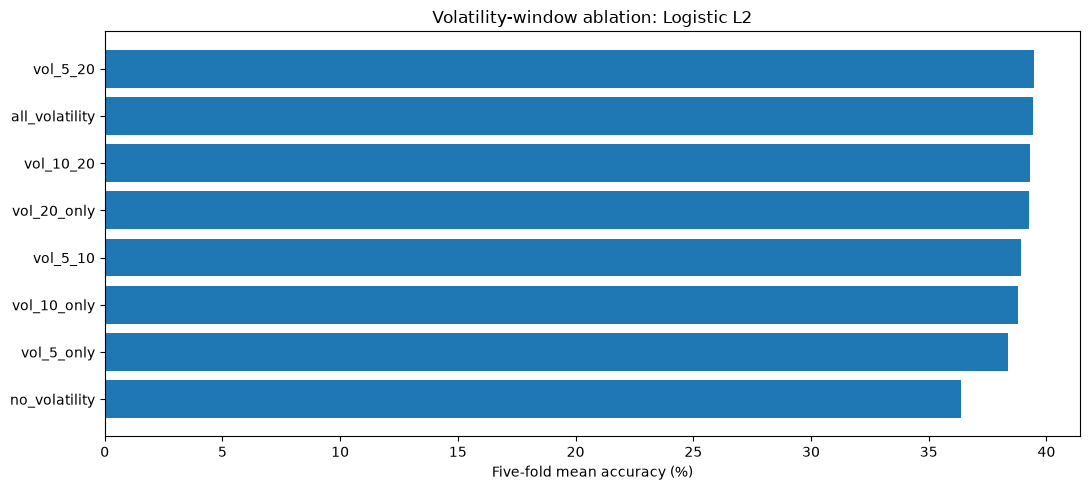

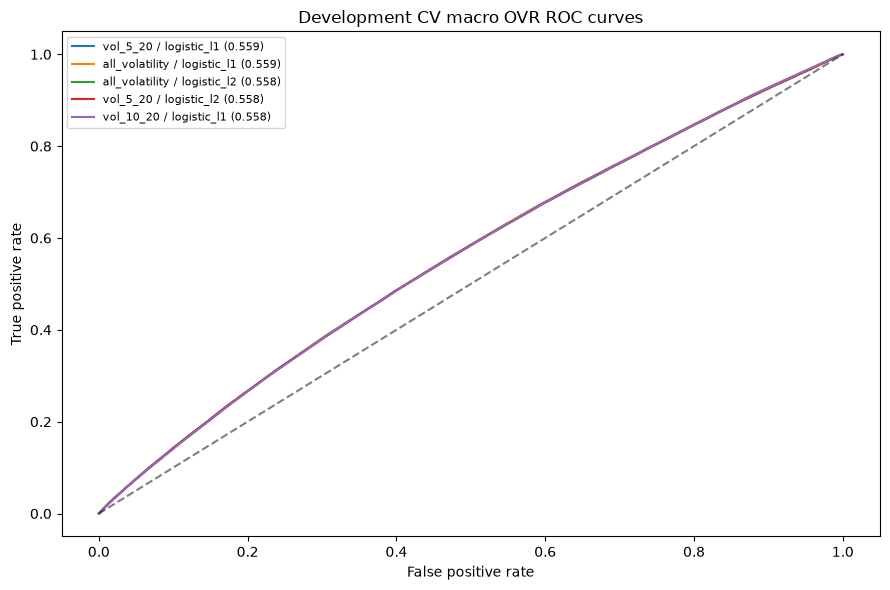

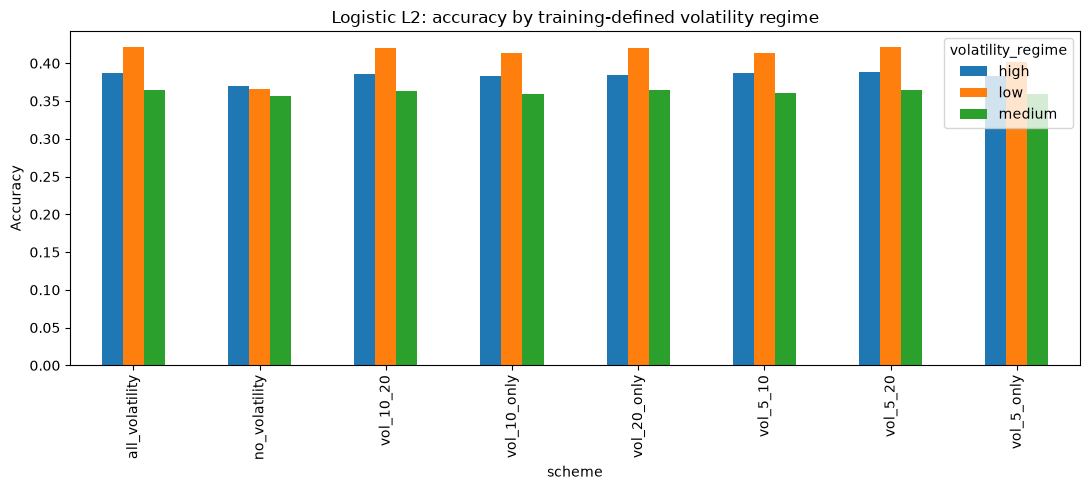

,scheme,model,accuracy,accuracy_std,balanced_accuracy,auc,auc_std,log_loss,fit_seconds
18,vol_5_20,logistic_l1,0.39549,0.02355,0.38299,0.55859,0.01237,1.08745,110.52504
0,all_volatility,logistic_l1,0.39521,0.02365,0.38274,0.55855,0.01250,1.08745,117.84923
1,all_volatility,logistic_l2,0.39419,0.02395,0.38242,0.55779,0.01421,1.08929,20.94494
19,vol_5_20,logistic_l2,0.39453,0.02380,0.38278,0.55773,0.01405,1.08935,20.75334
6,vol_10_20,logistic_l1,0.39440,0.02405,0.38196,0.55766,0.01273,1.08788,117.52003
12,vol_20_only,logistic_l1,0.39462,0.02371,0.38209,0.55733,0.01230,1.08797,92.37419
7,vol_10_20,logistic_l2,0.39298,0.02462,0.38121,0.55690,0.01448,1.08976,17.25065
13,vol_20_only,logistic_l2,0.39264,0.02359,0.38101,0.55641,0.01422,1.09010,18.35272
15,vol_5_10,logistic_l1,0.39047,0.02605,0.37932,0.55452,0.01329,1.08962,112.59570
9,vol_10_only,logistic_l1,0.38959,0.02595,0.37832,0.55383,0.01338,1.08983,95.78573


accuracy                                      \
scheme              all_volatility no_volatility vol_10_20 vol_10_only   
fold model                                                               
1    logistic_l1           0.36052       0.32875   0.35961     0.35098   
     logistic_l2           0.35870       0.33306   0.35705     0.34900   
     prior_baseline        0.26631       0.26631   0.26631     0.26631   
2    logistic_l1           0.40228       0.37398   0.40257     0.40179   
     logistic_l2           0.40411       0.37820   0.40479     0.40373   
     prior_baseline        0.31659       0.31659   0.31659     0.31659   
3    logistic_l1           0.41475       0.38793   0.41529     0.41114   
     logistic_l2           0.41584       0.38793   0.41426     0.41075   
     prior_baseline        0.40115       0.40115   0.40115     0.40115   
4    logistic_l1           0.41614       0.35919   0.41435     0.40903   
     logistic_l2           0.41133       0.36675   0.41079     0.40435   
     prior_baseline        0.39255       0.39255   0.39255     0.39255   
5    logistic_l1           0.38238       0.35153   0.38018     0.37500   
     logistic_l2           0.38098       0.35236   0.37804     0.37261   
     prior_baseline        0.34026       0.34026   0.34026     0.34026   

                                                              \
scheme              vol_20_only vol_5_10 vol_5_20 vol_5_only   
fold model                                                     
1    logistic_l1        0.35935  0.35208  0.36084    0.34711   
     logistic_l2        0.35692  0.35208  0.35880    0.34699   
     prior_baseline     0.26631  0.26631  0.26631    0.26631   
2    logistic_l1        0.40124  0.40131  0.40144    0.39219   
     logistic_l2        0.40318  0.40324  0.40402    0.39354   
     prior_baseline     0.31659  0.31659  0.31659    0.31659   
3    logistic_l1        0.41430  0.41249  0.41517    0.40740   
     logistic_l2        0.41307  0.41152  0.41555    0.40672   
     prior_baseline     0.40115  0.40115  0.40115    0.40115   
4    logistic_l1        0.41544  0.41088  0.41665    0.40319   
     logistic_l2        0.40935  0.40403  0.41204    0.39755   
     prior_baseline     0.39255  0.39255  0.39255    0.39255   
5    logistic_l1        0.38280  0.37561  0.38337    0.37577   
     logistic_l2        0.38069  0.37587  0.38225    0.37328   
     prior_baseline     0.34026  0.34026  0.34026    0.34026   

                    roc_auc_ovr_macro                ...                      \
scheme                 all_volatility no_volatility  ... vol_5_20 vol_5_only   
fold model                                           ...                       
1    logistic_l1              0.54107       0.51402  ...  0.54127    0.52932   
     logistic_l2              0.53813       0.51649  ...  0.53830    0.52620   
     prior_baseline           0.50000       0.50000  ...  0.50000    0.50000   
2    logistic_l1              0.57339       0.54235  ...  0.57326    0.55914   
     logistic_l2              0.57612       0.54741  ...  0.57595    0.56236   
     prior_baseline           0.50000       0.50000  ...  0.50000    0.50000   
3    logistic_l1              0.56392       0.53806  ...  0.56389    0.55637   
     logistic_l2              0.56399       0.53894  ...  0.56370    0.55632   
     prior_baseline           0.50000       0.50000  ...  0.50000    0.50000   
4    logistic_l1              0.56296       0.52075  ...  0.56295    0.55741   
     logistic_l2              0.55951       0.52684  ...  0.55942    0.55368   
     prior_baseline           0.50000       0.50000  ...  0.50000    0.50000   
5    logistic_l1              0.55141       0.52317  ...  0.55157    0.54333   
     logistic_l2              0.55121       0.52834  ...  0.55127    0.54322   
     prior_baseline           0.50000       0.50000  ...  0.50000    0.50000   

                                   accuracy                       \
scheme              all_minus_n

In [3]:
summary=plot_volatility(scores,curves,regimes,OUTPUT)
display(summary.round(5))
paired=scores.pivot_table(index=['fold','model'],columns='scheme',values=['accuracy','roc_auc_ovr_macro'])
for metric in ('accuracy','roc_auc_ovr_macro'):
    for scheme in ('no_volatility','vol_5_only','vol_10_only','vol_20_only'):
        paired[(metric,'all_minus_'+scheme)]=paired[(metric,'all_volatility')]-paired[(metric,scheme)]
display(paired.round(5))

## Volatility regimes and class distribution

Low, medium and high volatility groups use the **training fold’s** 20-bar volatility tertiles. This can reveal whether a classifier performs well only during high-volatility periods. It is a diagnostic, not a trading backtest.

In [4]:
display(regimes.groupby(['model','scheme','volatility_regime'],as_index=False).agg(
    accuracy=('accuracy','mean'),auc=('roc_auc_ovr_macro','mean'),n=('observations','sum')).round(5))
display(prevalence.pivot(index='fold',columns='class_id',values=['train_share','test_share']).round(4))
print('Saved to:',OUTPUT)

,model,scheme,volatility_regime,accuracy,auc,n
0,logistic_l1,all_volatility,high,0.38617,0.54971,43492
1,logistic_l1,all_volatility,low,0.42187,0.52459,57019
2,logistic_l1,all_volatility,medium,0.36647,0.53081,54883
3,logistic_l1,no_volatility,high,0.36437,0.53089,43492
4,logistic_l1,no_volatility,low,0.36142,0.51410,57019
...,...,...,...,...,...,...
67,prior_baseline,vol_5_20,low,0.40066,0.50000,57019
68,prior_baseline,vol_5_20,medium,0.33765,0.50000,54883
69,prior_baseline,vol_5_only,high,0.28260,0.50000,43492
70,prior_baseline,vol_5_only,low,0.40066,0.50000,57019


train_share                 test_share                
class_id           0       1       2          0       1       2
fold                                                           
1             0.3353  0.3329  0.3318     0.2663  0.3466  0.3871
2             0.3348  0.3330  0.3322     0.3626  0.3208  0.3166
3             0.3347  0.3330  0.3323     0.4011  0.2929  0.3060
4             0.3347  0.3330  0.3324     0.3926  0.3151  0.2923
5             0.3347  0.3329  0.3324     0.3403  0.3249  0.3348

Saved to: /home/oem/Documents/github/stock_ml_dynamic/artifacts/volatility_diagnostics/1d


## Interpretation checklist

1. Do shorter volatility windows outperform 20-bar volatility consistently in all five folds?
2. Does removing volatility reduce ROC-AUC and balanced accuracy as well as ordinary accuracy?
3. Is the improvement concentrated in one volatility regime or spread across low, medium, and high?
4. Are L1 coefficients converged? If not, treat its ranking cautiously.
5. **Do not evaluate the final 20% holdout in this notebook.**

A separate future experiment can compare volatility-scaled target definitions, but accuracy across differently defined targets is not directly comparable.